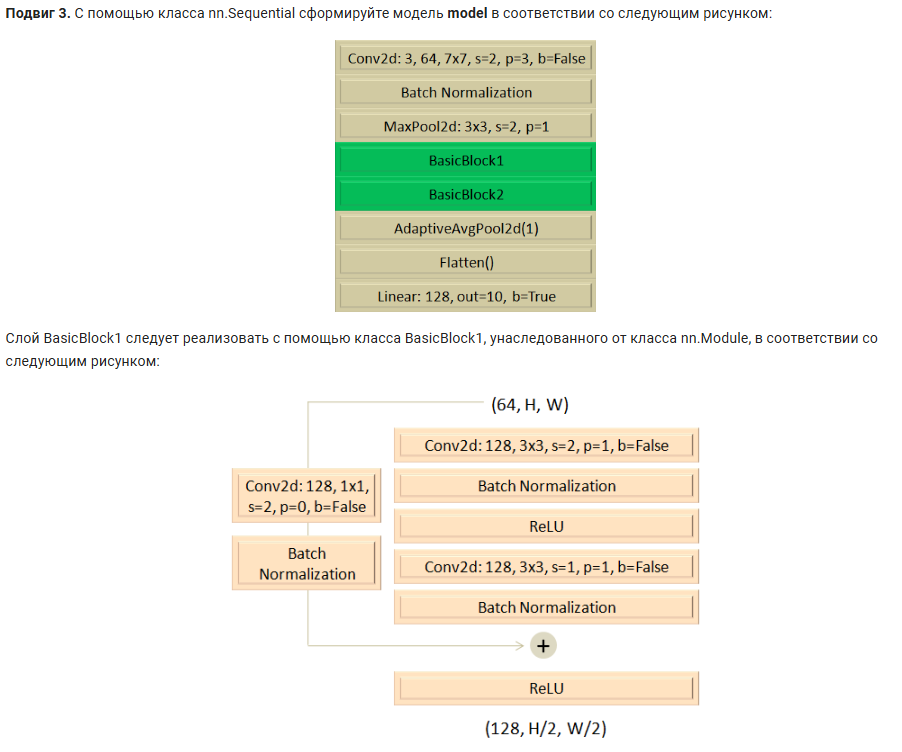

In [13]:
import torch
import torch.nn as nn

# здесь объявляйте классы BasicBlock1 и BasicBlock2


class BasicBlock1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128)
        )
        self.skip = nn.Sequential(
            nn.Conv2d(64, 128, 1, stride=2, padding=0, bias=False),
            nn.BatchNorm2d(128),
        )

    def forward(self, x):
        straight = self.net(x)
        skip = self.skip(x)
        return torch.relu(straight+skip)


class BasicBlock2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128)
        )

    def forward(self, x):
        return torch.relu(self.net(x) + x)

    
# здесь продолжайте программу
model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
    nn.BatchNorm2d(64),
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
    BasicBlock1(),
    BasicBlock2(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 10, bias=True)
)


batch_size = 8
x = torch.rand(batch_size, 3, 32, 32) # тензор x в программе не менять
model.eval()
predict = model(x)